In [1]:
# Cell 1: Import Library
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("Library Random Forest berhasil di-import")

Library Random Forest berhasil di-import


In [2]:
# Cell 2: Baca Dataset
df = pd.read_csv("dataset_kebun_pintar.csv")

print("Jumlah baris data:", len(df))
print("\nNama kolom:")
print(df.columns.tolist())

Jumlah baris data: 566

Nama kolom:
['timestamp_WIB', 'Kelembapan Tanah', 'Suhu lingkungan', 'Kondisi Tanah', 'pump_target', 'Suhu Air', 'Prediksi suhu air', 'Status pompa']


In [3]:
# Cell 3: Lihat 5 Data Pertama
df.head()

,timestamp_WIB,Kelembapan Tanah,Suhu lingkungan,Kondisi Tanah,pump_target,Suhu Air,Prediksi suhu air,Status pompa
0,10/13/2026 22:03,171,26.6,cukup,BELUM_PERLU_DISIRAM,NaN,NaN,NaN
1,10/13/2026 22:03,172,26.6,cukup,BELUM_PERLU_DISIRAM,NaN,NaN,NaN
2,10/13/2026 22:04,172,26.5,cukup,BELUM_PERLU_DISIRAM,NaN,NaN,NaN
3,10/13/2026 22:04,171,26.5,cukup,BELUM_PERLU_DISIRAM,NaN,NaN,NaN
4,10/13/2026 22:04,170,26.5,cukup,BELUM_PERLU_DISIRAM,NaN,NaN,NaN


In [4]:
# Cell 4: Info Dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 566 entries, 0 to 565
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   timestamp_WIB      566 non-null    str    
 1   Kelembapan Tanah   566 non-null    int64  
 2   Suhu lingkungan    566 non-null    float64
 3   Kondisi Tanah      566 non-null    str    
 4   pump_target        566 non-null    str    
 5   Suhu Air           0 non-null      float64
 6   Prediksi suhu air  0 non-null      float64
 7   Status pompa       0 non-null      float64
dtypes: float64(4), int64(1), str(3)
memory usage: 56.4 KB


In [5]:
# Cell 5: Cek Missing Value
print(df.isnull().sum())

timestamp_WIB          0
Kelembapan Tanah       0
Suhu lingkungan        0
Kondisi Tanah          0
pump_target            0
Suhu Air             566
Prediksi suhu air    566
Status pompa         566
dtype: int64


In [6]:
# Cell 6: Hapus Duplikat
print("Sebelum hapus duplikat:", len(df))
df = df.drop_duplicates()
print("Setelah hapus duplikat:", len(df))

Sebelum hapus duplikat: 566
Setelah hapus duplikat: 265


In [7]:
# Cell 7: Bersihkan Kondisi Tanah
print("Sebelum dibersihkan:")
print(df["Kondisi Tanah"].value_counts())

df["Kondisi Tanah"] = df["Kondisi Tanah"].str.lower().str.strip()

print("\nSetelah dibersihkan:")
print(df["Kondisi Tanah"].value_counts())

Sebelum dibersihkan:
Kondisi Tanah
kering    111
basah      85
cukup      69
Name: count, dtype: int64

Setelah dibersihkan:
Kondisi Tanah
kering    111
basah      85
cukup      69
Name: count, dtype: int64


In [8]:
# Cell 8: Mapping pump_target
print("Sebelum mapping:")
print(df["pump_target"].value_counts())

df["pump_target"] = df["pump_target"].map({
    "PERLU_DISIRAM": 1,
    "BELUM_PERLU_DISIRAM": 0
})

df = df.dropna(subset=["pump_target"])
df["pump_target"] = df["pump_target"].astype(int)

print("\nSetelah mapping:")
print(df["pump_target"].value_counts())

Sebelum mapping:
pump_target
BELUM_PERLU_DISIRAM    154
PERLU_DISIRAM          111
Name: count, dtype: int64

Setelah mapping:
pump_target
0    154
1    111
Name: count, dtype: int64


In [9]:
# Cell 9: Hapus Kolom yang Tidak Dipakai
df = df.drop(columns=["timestamp_WIB", "Suhu Air", "Prediksi suhu air", "Status pompa"], errors="ignore")

print("Kolom yang tersisa:")
print(df.columns.tolist())

Kolom yang tersisa:
['Kelembapan Tanah', 'Suhu lingkungan', 'Kondisi Tanah', 'pump_target']


In [10]:
# Cell 10: Encoding Kondisi Tanah
le_kondisi = LabelEncoder()
df["Kondisi_enc"] = le_kondisi.fit_transform(df["Kondisi Tanah"])

print("Hasil Encoding:")
print(dict(zip(le_kondisi.classes_, le_kondisi.transform(le_kondisi.classes_))))

Hasil Encoding:
{'basah': np.int64(0), 'cukup': np.int64(1), 'kering': np.int64(2)}


In [11]:
# Cell 11: Pisahkan Fitur dan Target
features = ["Kelembapan Tanah", "Suhu lingkungan", "Kondisi_enc"]

X = df[features]
y = df["pump_target"]

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
print("\nDistribusi target:")
print(y.value_counts())

Bentuk X: (265, 3)
Bentuk y: (265,)

Distribusi target:
pump_target
0    154
1    111
Name: count, dtype: int64


In [12]:
# Cell 12: Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data train:", len(X_train))
print("Data test :", len(X_test))

Data train: 212
Data test : 53


In [13]:
# Cell 13: Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling selesai")

Scaling selesai


In [14]:
# Cell 14: Training Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Model Random Forest berhasil di-training!")

Model Random Forest berhasil di-training!


In [15]:
# Cell 15: Evaluasi + Persentase Keberhasilan
y_pred = model.predict(X_test_scaled)

akurasi = accuracy_score(y_test, y_pred)
akurasi_persen = akurasi * 100

print("=" * 55)
print("          HASIL EVALUASI RANDOM FOREST")
print("=" * 55)
print(f"Tingkat Keberhasilan (Akurasi) : {akurasi_persen:.2f}%")
print(f"Akurasi (desimal)              : {akurasi:.4f}")
print("=" * 55)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["BELUM_PERLU", "PERLU_DISIRAM"]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

          HASIL EVALUASI RANDOM FOREST
Tingkat Keberhasilan (Akurasi) : 100.00%
Akurasi (desimal)              : 1.0000

Classification Report:
               precision    recall  f1-score   support

  BELUM_PERLU       1.00      1.00      1.00        31
PERLU_DISIRAM       1.00      1.00      1.00        22

     accuracy                           1.00        53
    macro avg       1.00      1.00      1.00        53
 weighted avg       1.00      1.00      1.00        53


Confusion Matrix:
[[31  0]
 [ 0 22]]


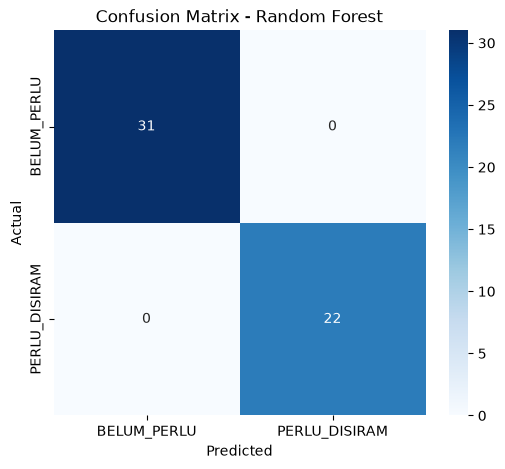

In [16]:
# Cell 16: Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["BELUM_PERLU", "PERLU_DISIRAM"],
            yticklabels=["BELUM_PERLU", "PERLU_DISIRAM"])
plt.title("Confusion Matrix - Random Forest")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

              Fitur  Importance
0  Kelembapan Tanah    0.488707
2       Kondisi_enc    0.423877
1   Suhu lingkungan    0.087416


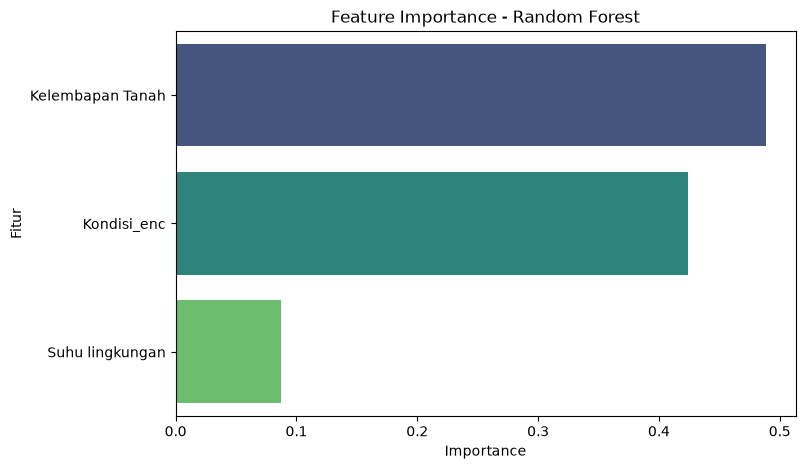

In [17]:
# Cell 17: Feature Importance
importance_df = pd.DataFrame({
    "Fitur": features,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print(importance_df)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x="Importance", y="Fitur", palette="viridis")
plt.title("Feature Importance - Random Forest")
plt.show()

In [18]:
# Cell 18: Simpan Model
joblib.dump(model, "model_rf.pkl")
joblib.dump(scaler, "scaler_rf.pkl")
joblib.dump(le_kondisi, "encoder_rf.pkl")

print("Model Random Forest berhasil disimpan!")

Model Random Forest berhasil disimpan!


In [19]:
# Cell 19: Cek Kelas Encoding
print("Kelas Kondisi Tanah yang dikenali:")
print(list(le_kondisi.classes_))

Kelas Kondisi Tanah yang dikenali:
['basah', 'cukup', 'kering']


In [20]:
# Cell 20: Fungsi Prediksi
def prediksi_rf(kelembapan_tanah, suhu_lingkungan, kondisi_tanah):
    
    if kondisi_tanah in le_kondisi.classes_:
        kondisi_enc = le_kondisi.transform([kondisi_tanah])[0]
    else:
        print(f"⚠️ Kondisi '{kondisi_tanah}' tidak dikenali. Menggunakan default 0")
        kondisi_enc = 0
    
    data = np.array([[kelembapan_tanah, suhu_lingkungan, kondisi_enc]])
    data_scaled = scaler.transform(data)
    
    hasil = model.predict(data_scaled)[0]
    proba = model.predict_proba(data_scaled)[0]
    
    print("\n" + "=" * 55)
    print("          HASIL PREDIKSI (Random Forest)")
    print("=" * 55)
    print(f"Kelembapan Tanah      : {kelembapan_tanah}")
    print(f"Suhu Lingkungan       : {suhu_lingkungan} °C")
    print(f"Kondisi Tanah         : {kondisi_tanah}")
    print("-" * 55)
    print(f"Hasil Prediksi (angka): {hasil}")
    
    if hasil == 1:
        print("Artinya               : PERLU DISIRAM → POMPA ON")
    else:
        print("Artinya               : BELUM PERLU DISIRAM → POMPA OFF")
    
    print("-" * 55)
    print(f"Probabilitas OFF      : {proba[0]*100:.2f}%")
    print(f"Probabilitas ON       : {proba[1]*100:.2f}%")
    print("-" * 55)
    print(f"Tingkat Keberhasilan Model : {akurasi_persen:.2f}%")
    print("=" * 55)
    
    return hasil

In [21]:
# Cell 21: Contoh Prediksi - Kering
prediksi_rf(
    kelembapan_tanah = 3155,
    suhu_lingkungan = 23.4,
    kondisi_tanah = "kering"
)


          HASIL PREDIKSI (Random Forest)
Kelembapan Tanah      : 3155
Suhu Lingkungan       : 23.4 °C
Kondisi Tanah         : kering
-------------------------------------------------------
Hasil Prediksi (angka): 1
Artinya               : PERLU DISIRAM → POMPA ON
-------------------------------------------------------
Probabilitas OFF      : 1.00%
Probabilitas ON       : 99.00%
-------------------------------------------------------
Tingkat Keberhasilan Model : 100.00%


np.int64(1)

In [22]:
# Cell 22: Contoh Prediksi - Cukup
prediksi_rf(
    kelembapan_tanah = 171,
    suhu_lingkungan = 26.6,
    kondisi_tanah = "cukup"
)


          HASIL PREDIKSI (Random Forest)
Kelembapan Tanah      : 171
Suhu Lingkungan       : 26.6 °C
Kondisi Tanah         : cukup
-------------------------------------------------------
Hasil Prediksi (angka): 0
Artinya               : BELUM PERLU DISIRAM → POMPA OFF
-------------------------------------------------------
Probabilitas OFF      : 100.00%
Probabilitas ON       : 0.00%
-------------------------------------------------------
Tingkat Keberhasilan Model : 100.00%


np.int64(0)

In [23]:
# Cell 23: Contoh Prediksi - Basah
prediksi_rf(
    kelembapan_tanah = 50,
    suhu_lingkungan = 33.1,
    kondisi_tanah = "basah"
)


          HASIL PREDIKSI (Random Forest)
Kelembapan Tanah      : 50
Suhu Lingkungan       : 33.1 °C
Kondisi Tanah         : basah
-------------------------------------------------------
Hasil Prediksi (angka): 0
Artinya               : BELUM PERLU DISIRAM → POMPA OFF
-------------------------------------------------------
Probabilitas OFF      : 100.00%
Probabilitas ON       : 0.00%
-------------------------------------------------------
Tingkat Keberhasilan Model : 100.00%


np.int64(0)